In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import matplotlib.tri as tri
import sys
sys.path.insert(0, 'ntasks_768/')
import DoubleLayerWithHoles_MPI_new_7 as DL
from matplotlib import path
from matplotlib import cm, ticker
import scipy as sc
import Geometries as geo

In [2]:
inside_solution = pd.read_csv('EigenvaluesEigenvectorsInsideSol_Dahne_MPI.csv', low_memory=False) 

In [3]:
inside_solution

,Eigenvalues,Eigenvectors0,Inside0,Inside1,Solution0,Eigenvalues.1,Eigenvectors0.1,Inside0.1,Inside1.1,Solution0.1,...,Eigenvalues.7,Eigenvectors0.7,Inside0.7,Inside1.7,Solution0.7,Eigenvalues_higher_precision,Eigenvectors_higher_precision0,Inside_higher_precision0,Inside_higher_precision1,Solution_higher_precision0
0,(5.075627639545353+1.1362589269877621e-08j),(-0.00039958024803722126-0.0001780615045236342j),-0.51250,-0.82,(4.775259451547046e-06+4.554578235094366e-06j),(7.861030412267473+1.0281929583309333e-06j),(0.00028418713311528337+0.00017214923994677149j),-0.51250,-0.82,(8.254507087738323e-05-0.00010203171971018512j),...,(8.65790995245536+3.334907402934811e-06j),(-0.002370823180639403-0.0008336984556381472j),-0.51250,-0.82,(0.00028197879126550494+0.0002716084877765791j),(7.861030412267473+1.0281929583309333e-06j),(0.00028418713311528337+0.00017214923994677149j),-0.50225,-0.861,(5.11062855323768e-06+1.4863515704543952e-06j)
1,NaN,(-0.00039217174773415294-0.00012991222813486306j),-0.46125,-0.82,(1.7107845218168113e-05+1.6504781274715092e-05j),NaN,(0.0005450550295584361-0.00016479835502548532j),-0.46125,-0.82,(0.000295674740418105-0.0003825299454027854j),...,NaN,(-0.0033089361426223976+0.00046694085237261075j),-0.46125,-0.82,(0.001006738439860799+0.0009729647905116798j),(7.861030570468253+8.833517678944665e-07j),(0.0005450550295584361-0.00016479835502548532j),-0.49200,-0.861,(1.6857478849782205e-05-1.8713904681416994e-05j)
2,NaN,(-0.0003825430975710491-6.090437754871942e-05j),-0.41000,-0.82,(2.5225066681209714e-05+2.4390319678876092e-05j),NaN,(0.0007284122115406479-0.0005061623147320724j),-0.41000,-0.82,(0.000423163999442848-0.0005894356506956253j),...,NaN,(-0.004483257332242929+0.0014990125626032072j),-0.41000,-0.82,(0.0014317258603441375+0.0013846189747566268j),(8.373379871149835+3.847558658760195e-06j),(0.0007284122115406479-0.0005061623147320724j),-0.48175,-0.861,(2.0165735890579316e-05-2.778355018524105e-05j)
3,NaN,(-0.000375377507205171-1.3974465718209167e-05j),-0.35875,-0.82,(3.288137940080369e-05+3.1785924437195895e-05j),NaN,(0.0007972578946684303-0.0007080843863387379j),-0.35875,-0.82,(0.0005181216551967321-0.0007864638011937763j),...,NaN,(-0.005215848457003089+0.0019582126201369053j),-0.35875,-0.82,(0.0017306616162057714+0.0016736085185892731j),NaN,(0.0007972578946684303-0.0007080843863387379j),-0.47150,-0.861,(2.4693142250727367e-05-3.497818377508162e-05j)
4,NaN,(-0.00035949406569268737+7.572123335659085e-05j),-0.30750,-0.82,(4.2323154469933794e-05+4.092182879775549e-05j),NaN,(0.0008369939161548801-0.0010615935396511877j),-0.30750,-0.82,(0.0006100369852179319-0.0010043083289445931j),...,NaN,(-0.006477791802911403+0.0025555129977410853j),-0.30750,-0.82,(0.0019961240346286317+0.0019304808511958144j),NaN,(0.0008369939161548801-0.0010615935396511877j),-0.46125,-0.861,(2.9838261449748483e-05-4.113948415177584e-05j)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23106,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.46125,0.861,(-2.983825365635625e-05+4.113947664674024e-05j)
23107,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.47150,0.861,(-2.4693134209524247e-05+3.497817653722e-05j)
23108,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.48175,0.861,(-2.0165727639727925e-05+2.7783543225619165e-05j)
23109,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.49200,0.861,(-1.6857470432802852e-05+1.8713897996283563e-05j)


In [4]:
xy_inside = inside_solution[['Inside0', 'Inside1']]
xy_inside = xy_inside.dropna(how="any")
xy_inside = xy_inside.to_numpy(dtype=float).T

In [5]:
sol = inside_solution['Solution0']
sol = sol.dropna(how="any")
sol = sol.to_numpy(dtype=np.complex128)

In [6]:
faces = np.array([21,55,55,55,55])
n = 2*faces
alpha = (1-np.sqrt(3/5))/2

#Parameters for the hexagon
n_gon_hexagon = 6
side_length = 1
R = side_length/(2*np.sin(np.pi/n_gon_hexagon))
xm = 0
ym = 0
rot = 0
hexagon = DL.create_polygon(n_gon_hexagon,R,xm,ym,rot,n[0])

# Parameters for the triangle
n_gon_triangle = 3
height = 6/27
R = height*2/3
distance = 14/27
angles = np.linspace(0,2*np.pi, n_gon_hexagon, endpoint=False)

xm = distance*np.cos(angles)
ym = distance*np.sin(angles)

rot1 = 2*np.pi/3
rot2 = 2*np.pi/(3*2)
hexagon_triangles = np.empty(n_gon_hexagon+1, dtype=object)
hexagon_triangles[0] = hexagon

# Create 6 triangles at the correct positions
for i in range(n_gon_hexagon):
    if np.mod(i,2) == 0:
        triangle_temp = DL.create_polygon(n_gon_triangle,R,xm[i],ym[i],rot1,n[1])
    else:
        triangle_temp = DL.create_polygon(n_gon_triangle,R,xm[i],ym[i],rot2,n[1])
    tringle_flip = np.flip(triangle_temp,1)
    hexagon_triangles[i+1] = tringle_flip

# Stack all the boundaries together
vi = np.copy(hexagon_triangles)
collocation_nodes = np.empty(n_gon_hexagon+1, dtype= object)
for i in range(n_gon_hexagon+1):
    collocation_nodes[i] = DL.create_collocation_nodes(vi[i],alpha) 

In [7]:
hexagon_triangles_closed_curve = np.empty(n_gon_hexagon+1,dtype=object)
for i in range(n_gon_hexagon+1):
    hexagon_triangles_closed_curve[i] = np.hstack((hexagon_triangles[i],hexagon_triangles[i][:,0:1]))

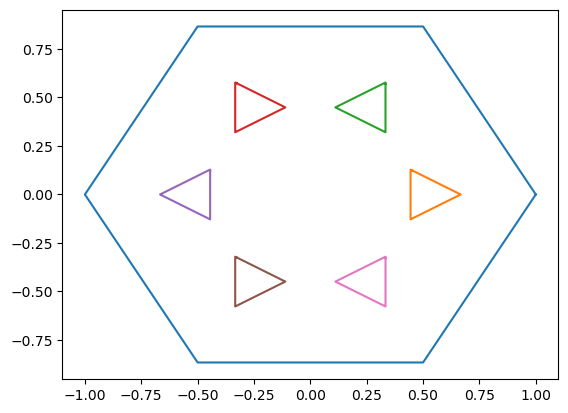

In [8]:
for i in range(n_gon_hexagon+1):
    plt.plot(hexagon_triangles_closed_curve[i][0,:], hexagon_triangles_closed_curve[i][1,:])

In [9]:
def ray_tracing_in_holes(boundary, xmid, ymid):
    """
    Routine to find all the points of a square on an equidistant grid, that lie within the given domain without the given holes.

    Parameters
    ----------
    boundary : numpy.ndarray
        Array containing the vertices and midpoints for each of the approximated boundaries.
    x_start : float
        Start value of a square in x-direction.
    x_end : float
        End value of a square in x-direction.
    x_steps : int
        Number of points in x-direction that should be checked to be inside the given domain without holes.
    y_start : float
        Start value of a square in y-direction.
    y_end : float
        End value of a square in y-direction.
    y_steps : int
        Number of points in y-direction that should be checked to be inside the given domain without holes.

    Returns
    -------
    xy_inside : numpy.ndarray
        Numpy array containing all points that lie inside of the given domain without the holes.
    """
    # Create a path for the boundary of the holes
    p = [path.Path(boundary[i].T) for i in range(boundary.shape[0])]    
    # Create the mesh of the square to be checked, whether they are inside or outside of the domain with holes.
    mesh = np.stack((xmid,ymid),axis = 1)
    # Check whether the mesh is inside or outside of the outer boundary of the domain (without holes).
    inside = np.array([p[i].contains_points(mesh) for i in range(boundary.shape[0])])
    inside_any = np.any(inside, axis=0)
    return inside_any

In [10]:
eigenvalues = inside_solution['Eigenvalues'][0]
eigenvalues

'(5.075627639545353+1.1362589269877621e-08j)'

In [11]:
5.075627639545353 * 5.075627639545353

25.761995935316726

In [11]:
eigenvalues = inside_solution['Eigenvalues.1'][0]
eigenvalues

'(7.861030412267473+1.0281929583309333e-06j)'

In [12]:
7.861030412267473 * 7.861030412267473

61.79579914259412

In [12]:
eigenvalues = inside_solution['Eigenvalues.2'][0]
eigenvalues

'(7.861030570468253+8.833517678944665e-07j)'

In [14]:
7.861030570468253 * 7.861030570468253

61.79580162983642

In [15]:
eigenvalues = inside_solution['Eigenvalues.3'][0]
eigenvalues

'(8.373379871149835+3.847558658760195e-06j)'

In [16]:
8.373379871149835 * 8.373379871149835

70.11349046657722

In [17]:
(8.373379871149835+3.847558658760195e-06j)* (8.373379871149835+3.847558658760195e-06j)

(70.11349046656241+6.443414045266175e-05j)